# Phase 7A – Financial models (Parts 2–5)

**Everything here is an illustrative reference facility, not company economics.** No Micron, Tata, CG or Kaynes profit is claimed.

What this notebook does:
- **Part 2. Reference OSAT:** a CG-Semi-sized plant. What margin and IRR does it earn under each subsidy case?
- **Part 3. Reference fab:** a Dholera-sized plant, with tools installed in phases. What loading does it need to break even, with and without the subsidy?
- **Part 4. Correlated Monte Carlo:** re-run Sanand (Phase 5) and Dholera (Phase 6) with utilisation and price moving together.
- **Part 5. India 2030 summary:** how much of India's chip market is made, supplied or value-added locally.

**Rules:**
- One FX rate: ₹95/$.
- Inputs come from `data/*_inputs.csv`, which carry source columns.
- Outputs go to `data/*.csv` for the Excel workbook (chat 7B).

In [1]:
import pandas as pd, numpy as np, math
import matplotlib.pyplot as plt
pd.set_option('display.width', 170); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
FX = 95

def irr(cfs, lo=-0.9, hi=1.5):
    # IRR by bisection: the rate at which NPV = 0. Returns NaN if NPV never changes sign.
    npv = lambda r: sum(cf / (1 + r) ** t for t, cf in enumerate(cfs))
    if npv(lo) * npv(hi) > 0:
        return float('nan')
    for _ in range(200):
        mid = (lo + hi) / 2
        if npv(lo) * npv(mid) <= 0: hi = mid
        else: lo = mid
    return mid

def payback(cfs):
    # first year (counting from year 0) in which cumulative cash flow turns positive
    c = np.cumsum(cfs)
    pos = np.where(c >= 0)[0]
    return int(pos[0]) if len(pos) else None

## Part 2 – Reference OSAT facility

**Size:** ₹7,584 crore of capex and 4,044M units a year. This matches CG Semi at Sanand, the mid-sized Indian OSAT that has a stated full-ramp revenue target (US$500M). Using that plant means the revenue assumption is a disclosed target, not my guess.

**Step 1. Price per unit.**
- Full-ramp revenue = capex × revenue/capex ratio (0.625, corrected in Part 1).
- Price per unit = full-ramp revenue ÷ units at full-ramp loading (85%).

Amkor does not disclose unit volumes, so a per-unit cross-check against Amkor is not possible. The check is instead at margin level (step 3).

In [2]:
oi = pd.read_csv('../data/osat_inputs.csv').set_index('input')
v = lambda k: float(oi.loc[k, 'value'])
CAPEX = v('capex_rs_cr'); CAPU = v('capacity_m_units_yr'); RATIO = v('revenue_to_capex'); UFULL = v('full_ramp_utilisation')
REV_FULL = CAPEX * RATIO                                  # Rs crore a year at full ramp
PRICE = REV_FULL * 1e7 / (CAPU * 1e6 * UFULL)              # Rs per unit
print(f'Full-ramp revenue: Rs{REV_FULL:,.0f} Cr (US${REV_FULL*1e7/FX/1e6:,.0f}M)')
print(f'Price per unit: Rs{PRICE:.2f} = US${PRICE/FX:.3f}  (at {UFULL:.0%} of {CAPU:,.0f}M units)')

Full-ramp revenue: Rs4,740 Cr (US$499M)
Price per unit: Rs13.79 = US$0.145  (at 85% of 4,044M units)


**Step 2. Adjust Amkor's cost structure for India** (JETRO FY2024 survey, Oct–Nov 2024; errata checked: its only correction is Tokyo water, so none of these figures change).

- **Labour:** Ahmedabad wages compared with Amkor's South-East Asian locations (Manila, Kuala Lumpur, Hanoi, HCMC), averaging workers and engineers 50/50. Korea and Japan are not in this survey; including them would make India's advantage larger.
- **Power:** Ahmedabad energy charge (UGVCL) compared with the same cities, before and after Gujarat's ₹2/kWh subsidy. JETRO's Ahmedabad rate is the energy charge only, so India's all-in power cost is higher than shown. I treat this as an upper bound on India's advantage.

In [3]:
jc = pd.read_csv('../data/jetro_costs.csv')
def num(x):
    a = [float(t) for t in str(x).split('-')]
    return sum(a) / len(a)            # midpoint of a range like '0.05-0.09'
w = jc[jc['item'].isin(['worker_monthly', 'engineer_monthly'])].copy()
w['usd'] = w['usd'].astype(float)
wp = w.pivot(index='city', columns='item', values='usd')
sea = ['Manila', 'Kuala Lumpur', 'Hanoi', 'Ho Chi Minh City']
lab_factor = 0.5 * wp.loc['Ahmedabad', 'worker_monthly'] / wp.loc[sea, 'worker_monthly'].mean() + \
             0.5 * wp.loc['Ahmedabad', 'engineer_monthly'] / wp.loc[sea, 'engineer_monthly'].mean()
print(wp.round(0)); print(f'India labour cost factor vs SE-Asian Amkor sites: {lab_factor:.2f}')

p = jc[jc['item'] == 'industrial_power_per_kwh'].set_index('city')['usd'].map(num)
p_sea = p[['Manila', 'Kuala Lumpur', 'Hanoi']].mean()        # Hanoi and HCMC share one national tariff
p_in = num('2.65-4.90') / 84.0886                            # JETRO's Rs figure at JETRO's own rate
p_in_sub = (num('2.65-4.90') - v('gujarat_power_subsidy_rs_kwh')) / 84.0886
pow_factor, pow_factor_sub = p_in / p_sea, p_in_sub / p_sea
print(f'Power US$/kWh: India {p_in:.3f} (with Gujarat subsidy {p_in_sub:.3f}); SE Asia avg {p_sea:.3f}')
print(f'Power cost factor: {pow_factor:.2f} without subsidy, {pow_factor_sub:.2f} with')

item              engineer_monthly  worker_monthly
city                                              
Ahmedabad                    589.0           287.0
Hanoi                        520.0           278.0
Ho Chi Minh City             619.0           329.0
Kuala Lumpur                 917.0           490.0
Manila                       478.0           314.0
India labour cost factor vs SE-Asian Amkor sites: 0.87
Power US$/kWh: India 0.045 (with Gujarat subsidy 0.021); SE Asia avg 0.128
Power cost factor: 0.35 without subsidy, 0.16 with


**Step 3. The cost template**, as a share of revenue at full ramp:
- **Materials:** 55% (Amkor). Variable: it moves with volume.
- **Power:** 3% for Amkor × India power factor. Variable.
- **Labour:** 10% for Amkor × India labour factor. Treated as fixed, because staff are hired for the plant.
- **Other cost of sales:** 9% (Amkor's other 12%, minus power). Fixed.
- **R&D + SG&A:** 7.0% (Amkor 2025). Fixed.
- **Depreciation:** capex × (1 − support) ÷ 7 years. Support is paid against capex, so it shrinks the depreciable base (the net method, as in Phase 3).

**Break-even utilisation** is where gross margin = 0:

  U_be = U_full × fixed cost of sales ÷ (revenue − variable cost), all at full ramp.

**IRR** (pre-tax, simple, explainable):
- year 0 = −capex × (1 − support);
- years 1–10 = EBITDA, ramping 30 / 55 / 75 / 85% loading;
- no tax, working capital, replacement capex or terminal value.

In [4]:
MAT, OTH, OPEX = v('materials_pct_sales'), v('other_cogs_pct_sales_amkor') - v('power_pct_sales_amkor'), v('opex_pct_sales')
LAB = v('labour_pct_sales_amkor') * lab_factor
RAMP = [0.30, 0.55, 0.75] + [0.85] * 7

def osat(support, util_full=UFULL, price_mult=1.0, mat=MAT, power_sub=True, power_pct=v('power_pct_sales_amkor')):
    pw = power_pct * (pow_factor_sub if power_sub else pow_factor)
    rev_full = CAPU * 1e6 * util_full * PRICE * price_mult / 1e7           # Rs Cr at full ramp
    # cost lines in Rs Cr at full ramp (shares are of the base full-ramp revenue)
    fixed_cash = (LAB + OTH + OPEX) * REV_FULL
    fixed_cogs = (LAB + OTH) * REV_FULL
    dep = CAPEX * (1 - support) / 7
    var_per_rev = (mat + pw) / price_mult        # materials and power are per unit, so their share falls if price rises
    gm_full = rev_full * (1 - var_per_rev) - fixed_cogs - dep
    ebitda_full = rev_full * (1 - var_per_rev) - fixed_cash
    u_be = util_full * (fixed_cogs + dep) / (rev_full * (1 - var_per_rev))
    cfs = [-CAPEX * (1 - support)]
    for u in [min(r, util_full) if r < 0.85 else util_full for r in RAMP]:
        rev = rev_full * u / util_full
        cfs.append(rev * (1 - var_per_rev) - fixed_cash)
    return {'support_%': round(100 * support), 'revenue_full_rs_cr': round(rev_full), 'gross_margin_%': round(100 * gm_full / rev_full, 1),
            'ebitda_margin_%': round(100 * ebitda_full / rev_full, 1), 'depreciation_%_rev': round(100 * dep / rev_full, 1),
            'breakeven_util_%': round(100 * u_be), 'payback_yr': payback(cfs) if payback(cfs) is not None else 'not in 10 yrs', 'irr_%': round(100 * irr(cfs), 1)}, cfs

cases = [(0.0, 'No support'), (0.35, 'Semicon 2.0 legacy (25% + Gujarat 10%)'), (0.49, 'Semicon 2.0 advanced (35% + Gujarat 14%)'),
         (0.50, 'Semicon 1.0 central only'), (0.65, 'Semicon 1.0 + Gujarat (~65% in PV)')]
osat_cases = pd.DataFrame([{'case': n, **osat(s)[0]} for s, n in cases])
print(f'Cost shares at full ramp: materials {MAT:.0%}, labour {LAB:.1%}, power {v("power_pct_sales_amkor")*pow_factor_sub:.1%}, other {OTH:.0%}, opex {OPEX:.0%}')
osat_cases

Cost shares at full ramp: materials 55%, labour 8.7%, power 0.5%, other 9%, opex 7%


,case,support_%,revenue_full_rs_cr,gross_margin_%,ebitda_margin_%,depreciation_%_rev,breakeven_util_%,payback_yr,irr_%
0,No support,0,4740,3.9,19.8,22.9,77,not in 10 yrs,-1.1
1,Semicon 2.0 legacy (25% + Gujarat 10%),35,4740,11.9,19.8,14.9,62,8,5.4
2,Semicon 2.0 advanced (35% + Gujarat 14%),49,4740,15.1,19.8,11.7,56,7,9.3
3,Semicon 1.0 central only,50,4740,15.4,19.8,11.4,56,7,9.7
4,Semicon 1.0 + Gujarat (~65% in PV),65,4740,18.8,19.8,8.0,49,6,15.9


**Reading this:**
- **EBITDA:** the reference OSAT earns an EBITDA margin a little above Amkor's 17.3%, because Indian labour and power are cheaper. Those are small effects: about 1–2 points of revenue, as Phase 4 found.
- **Depreciation:** the subsidy is the big lever. Without support, depreciation takes over a fifth of revenue and gross margin is close to zero. With ~65% support, the gross margin is above Amkor's 14%.
- **Returns:** without support the 10-year IRR is negative and there is no payback. With ~65% support the IRR is in the mid-teens with payback in about six years.

**What this means:** for a legacy OSAT, India's cost advantage is mainly the capital subsidy, not wages. Semicon 2.0's 25% legacy-packaging rate (35% with Gujarat) leaves a much thinner case than Semicon 1.0's ~65%. That supports the policy shift towards advanced packaging, where Semicon 2.0 pays more.

Price -20% at 65% support: {'support_%': 65, 'revenue_full_rs_cr': 3792, 'gross_margin_%': np.float64(-1.5), 'ebitda_margin_%': np.float64(-0.3), 'depreciation_%_rev': 10.0, 'breakeven_util_%': 89, 'payback_yr': 'not in 10 yrs', 'irr_%': nan}


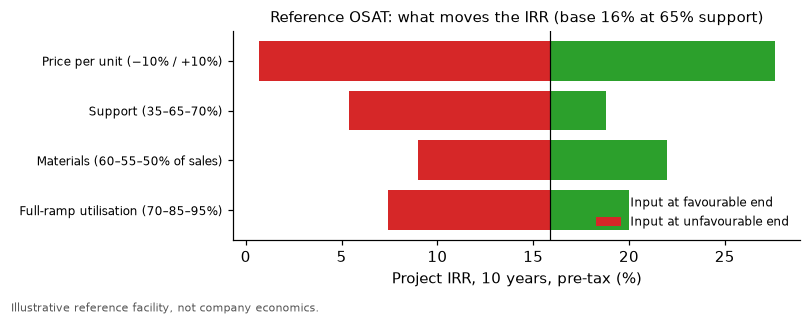

,input,low_case_irr_%,high_case_irr_%,swing
0,Full-ramp utilisation (70–85–95%),7.4,20.0,12.6
2,Materials (60–55–50% of sales),9.0,22.0,13.0
3,Support (35–65–70%),5.4,18.8,13.4
1,Price per unit (−10% / +10%),0.7,27.6,26.9


In [5]:
base = osat(0.65)[0]['irr_%']
tor_o = []
for lab, kw_lo, kw_hi in [('Full-ramp utilisation (70–85–95%)', {'util_full': 0.70}, {'util_full': 0.95}),
                          ('Price per unit (−10% / +10%)', {'price_mult': 0.9}, {'price_mult': 1.1}),
                          ('Materials (60–55–50% of sales)', {'mat': 0.60}, {'mat': 0.50}),
                          ('Support (35–65–70%)', {}, {})]:
    if lab.startswith('Support'):
        lo, hi = osat(0.35)[0]['irr_%'], osat(0.70)[0]['irr_%']
    else:
        lo, hi = osat(0.65, **kw_lo)[0]['irr_%'], osat(0.65, **kw_hi)[0]['irr_%']
    tor_o.append({'input': lab, 'low_case_irr_%': lo, 'high_case_irr_%': hi})
print('Price -20% at 65% support:', osat(0.65, price_mult=0.8)[0])
tor_o = pd.DataFrame(tor_o); tor_o['swing'] = tor_o['high_case_irr_%'] - tor_o['low_case_irr_%']; tor_o = tor_o.sort_values('swing')
fig, ax = plt.subplots(figsize=(7.4, 2.9)); yy = np.arange(len(tor_o))
ax.barh(yy, tor_o['high_case_irr_%'] - base, left=base, color='#2ca02c', label='Input at favourable end')
ax.barh(yy, tor_o['low_case_irr_%'] - base, left=base, color='#d62728', label='Input at unfavourable end')
ax.axvline(base, color='black', lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(tor_o['input'], fontsize=8)
ax.set_xlabel('Project IRR, 10 years, pre-tax (%)'); ax.set_title(f'Reference OSAT: what moves the IRR (base {base:.0f}% at 65% support)', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='lower right')
fig.text(0.01, 0.005, 'Illustrative reference facility, not company economics.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart_osat_tornado.png', dpi=200); plt.show()
tor_o

**Reading this:** a 10% move in price per unit moves the IRR about as much as the whole support range. Packaging fees are thin: materials take 55% of every rupee, so a price cut comes almost straight out of margin. A 20% price cut (printed above) wipes out EBITDA altogether. Loading, materials and the support rate come next.

## Part 3 – Reference fab (Dholera-sized)

**Capex split.** SIA–BCG (Sep 2020, p.19) says about half of new-fab capex is equipment and 20–40% is construction. So:
- **Tools:** 50% (range 50–65%), depreciated over 5 years from the year installed (TSMC; UMC uses 6).
- **Building, cleanroom, utilities:** 30%, depreciated over 20 years from commissioning in 2028, at full size from day one.
- **Other:** 20% (land, interest during construction, technology licence). Not depreciated here.

**Tool-in phases (assumption).** Installed capacity is 5k → 15k → 20k → 30k → 40k → 50k wspm over 2028–2033. Loading of installed tools is 50 → 60 → 62.5 → 75 → 85 → 85%. Their product matches Phase 6's design-capacity utilisation (5 / 18 / 25 / 45 / 68.5%), so this model is consistent with the Monte Carlo. Loading is now on installed capacity, the same basis as the peers' 46–88% break-evens.

**Costs per wafer, from UMC 2025:**
- cost of sales per wafer = US$1,973 × (1 − 29%) = US$1,401;
- 36.1% of that is variable (materials, chemicals, power) = **US$506 per wafer started**;
- the fixed 63.9% minus UMC's depreciation (21.2% of revenue) is fixed cash cost: about US$477 per wafer at UMC's 75% loading. I turn this into a cost per installed wafer of capacity a year;
- R&D + SG&A = 11.3% of revenue (UMC).

**Support** is paid against capex (pari-passu), so it cuts cash capex and the depreciable base.

**Capex timing:** building and other spent 2026–27, tools in their install year. Cash flows run 2026–2037. IRR adds the remaining book value at end-2037 as a terminal value, because the fab keeps running after 2037.

In [6]:
fi = pd.read_csv('../data/fab_inputs.csv').set_index('input')
fv = lambda k: float(fi.loc[k, 'value'])
CAPX = fv('capex_rs_cr') * 1e7 / FX / 1e6                   # US$ M
INST = [5000, 15000, 20000, 30000, 40000, 50000]            # installed wspm 2028-2033
LOAD = [0.50, 0.60, 0.625, 0.75, 0.85, 0.85]
YLD = [0.75, 0.85, 0.90, 0.93, 0.95]
P_MED, P_MIN, P_MAX = fv('price_usd_wafer'), float(fi.loc['price_usd_wafer', 'low']), float(fi.loc['price_usd_wafer', 'high'])
cogs_w = fv('umc_rev_per_wafer_2025') * (1 - fv('umc_gm_2025'))
VAR_W = cogs_w * (1 - fv('umc_fixed_share_of_cogs'))
FIX_W = cogs_w * fv('umc_fixed_share_of_cogs') - fv('umc_rev_per_wafer_2025') * fv('umc_dep_pct_revenue_2025')
FIX_CAP = FIX_W * fv('umc_util_2025')                        # US$ per wafer of installed capacity per year
OPEXR = fv('umc_opex_pct_revenue_2025')
print(f'Capex US${CAPX:,.0f}M at Rs95 | UMC cost of sales/wafer US${cogs_w:,.0f} -> variable US${VAR_W:,.0f}, fixed cash US${FIX_W:,.0f}/wafer, US${FIX_CAP:,.0f} per wafer-of-capacity/yr')

Capex US$9,634M at Rs95 | UMC cost of sales/wafer US$1,401 -> variable US$506, fixed cash US$477/wafer, US$358 per wafer-of-capacity/yr


In [7]:
YEARS = list(range(2026, 2038))
def fab(support=0.65, price=P_MED, var_mult=1.0, load_mult=1.0, yield_add=0.0, equip=0.50, tool_life=5, building=0.30, eligible_only=False):
    other = 1 - equip - building
    rows, tranche = [], {}
    prev_inst = 0
    for y in YEARS:
        i = min(max(y - 2028, 0), 5)
        inst = INST[i] if y >= 2028 else 0
        load = min(LOAD[i] * load_mult, 1.0) if y >= 2028 else 0
        yl = min(YLD[min(max(y - 2028, 0), 4)] + yield_add, 0.99)
        add = inst - prev_inst; prev_inst = inst
        if add > 0: tranche[y] = CAPX * equip * add / 50000
        starts = inst * 12 * load
        rev = starts * yl * price / 1e6
        var = starts * VAR_W * var_mult / 1e6
        fixed = inst * 12 * FIX_CAP / 1e6
        opex = OPEXR * rev
        dep_b = CAPX * building * (1 - support) / 20 if y >= 2028 else 0
        dep_t = sum(c * (1 - support) / tool_life for ty, c in tranche.items() if ty <= y < ty + tool_life)
        capex = (CAPX * (building + other) / 2 if y in (2026, 2027) else 0) + (tranche[y] if add > 0 else 0)
        rows.append({'year': y, 'installed_wspm': inst, 'loading_%': round(100 * load, 1), 'yield_%': round(100 * yl), 'wafers_out_k': round(starts * yl / 1e3),
                     'revenue_usd_m': rev, 'variable_usd_m': var, 'fixed_cash_usd_m': fixed, 'opex_usd_m': opex, 'dep_building_usd_m': dep_b,
                     'dep_tools_usd_m': dep_t, 'gross_profit_usd_m': rev - var - fixed - dep_b - dep_t,
                     'ebitda_usd_m': rev - var - fixed - opex, 'net_capex_usd_m': capex * (1 - support) + (support * CAPX * other / 2 if eligible_only and y in (2026, 2027) else 0)})  # eligible_only: Semicon 2.0 rules, 'other' (land, IDC, licence) gets no support
    df = pd.DataFrame(rows)
    df['cash_flow_usd_m'] = df['ebitda_usd_m'] - df['net_capex_usd_m']
    # book value left at end-2037 (terminal value for IRR)
    bv_b = CAPX * building * (1 - support) * (1 - 10 / 20)
    bv_t = sum(c * (1 - support) * max(0, 1 - (2037 - ty + 1) / tool_life) for ty, c in tranche.items())
    tv = bv_b + bv_t + CAPX * other * (1 - support) * 0      # other (land/IDC/licence) not counted as recoverable
    cfs = list(df['cash_flow_usd_m']); cfs[-1] += tv
    return df, irr(cfs), payback(list(df['cash_flow_usd_m'])), tv

SUSTAIN = 0.10   # sustaining capex after full tool-in, share of revenue (assumption; UMC 2025 total capex was ~20% of revenue incl. expansion)
def fab20(support=0.65, **kw):
    # 20 years of operation (2028-2047), no terminal value: years after 2037 repeat 2037's EBITDA minus sustaining capex
    df, _, _, _ = fab(support, **kw)
    cfs = list(df['cash_flow_usd_m'])
    last = df.iloc[-1]
    cfs += [last['ebitda_usd_m'] - SUSTAIN * last['revenue_usd_m']] * 10
    cfs = [c - (SUSTAIN * r if 2034 <= y <= 2037 else 0) for c, r, y in zip(cfs[:12], list(df['revenue_usd_m']), YEARS)] + cfs[12:]
    pb = payback(cfs)
    return irr(cfs), (2026 + pb if pb is not None else None)

def breakeven_loading(df, year, price=P_MED):
    r = df[df.year == year].iloc[0]
    cap_yr = r['installed_wspm'] * 12
    yl = r['yield_%'] / 100
    margin_per_start = price * yl - VAR_W
    gm_be = (r['fixed_cash_usd_m'] + r['dep_building_usd_m'] + r['dep_tools_usd_m']) * 1e6 / (cap_yr * margin_per_start)
    cash_be = r['fixed_cash_usd_m'] * 1e6 / (cap_yr * (price * yl * (1 - OPEXR) - VAR_W))
    return 100 * gm_be, 100 * cash_be

base_df, base_irr, base_pb, base_tv = fab(0.65)
show = base_df[base_df.year >= 2028].copy()
for c in [c for c in show.columns if c.endswith('usd_m')]: show[c] = show[c].round(0)
show['gross_margin_%'] = (100 * show['gross_profit_usd_m'] / show['revenue_usd_m']).round(0)
show['ebitda_margin_%'] = (100 * show['ebitda_usd_m'] / show['revenue_usd_m']).round(0)
print(f'Base case, 65% support: project IRR {100*base_irr:.1f}% (incl. book value US${base_tv:,.0f}M at end-2037), payback year index {base_pb}')
show[['year', 'installed_wspm', 'loading_%', 'yield_%', 'wafers_out_k', 'revenue_usd_m', 'gross_profit_usd_m', 'gross_margin_%', 'ebitda_usd_m', 'ebitda_margin_%', 'cash_flow_usd_m']]

Base case, 65% support: project IRR 1.4% (incl. book value US$506M at end-2037), payback year index None


,year,installed_wspm,loading_%,yield_%,wafers_out_k,revenue_usd_m,gross_profit_usd_m,gross_margin_%,ebitda_usd_m,ebitda_margin_%,cash_flow_usd_m
2,2028,5000,50.0,75,22,50.0,-71.0,-142.0,7.0,14.0,-161.0
3,2029,15000,60.0,85,92,203.0,-68.0,-33.0,61.0,30.0,-276.0
4,2030,20000,62.5,90,135,298.0,-49.0,-16.0,103.0,35.0,-66.0
5,2031,30000,75.0,93,251,554.0,36.0,6.0,226.0,41.0,-111.0
6,2032,40000,85.0,95,388,856.0,157.0,18.0,381.0,45.0,44.0
7,2033,50000,85.0,95,484,1070.0,243.0,23.0,476.0,44.0,139.0
8,2034,50000,85.0,95,484,1070.0,311.0,29.0,476.0,44.0,476.0
9,2035,50000,85.0,95,484,1070.0,344.0,32.0,476.0,44.0,476.0
10,2036,50000,85.0,95,484,1070.0,412.0,39.0,476.0,44.0,476.0
11,2037,50000,85.0,95,484,1070.0,479.0,45.0,476.0,44.0,476.0


### Break-even loading of installed capacity, with and without support

For a given year, gross margin = 0 when:

  loading = (fixed cash cost + depreciation) ÷ (installed capacity × (price × yield − variable cost per wafer started))

I also show the **cash** break-even (EBITDA = 0, ignoring depreciation). That is the loading the fab needs just to stop burning cash.

In [8]:
# Semicon 2.0 appears twice: 56% of total capex (upper bound), and 56% of eligible capex only (~45% of total; same break-even, because 'other' is never depreciated).
fab_cases = [(0.0, 'No support', False), (0.50, 'Central 50% only', False), (0.56, 'Semicon 2.0 + Gujarat (up to 56%)', False),
             (0.56, 'Semicon 2.0 + Gujarat (eligible capex, ~45% of total)', True), (0.65, 'Semicon 1.0 + Gujarat (~65% PV)', False)]
be_rows = []
for s, name, elig in fab_cases:
    df, r_, pb, tv = fab(s, eligible_only=elig)
    row = {'case': name, 'support_%': round(100 * s)}
    for y in [2030, 2033, 2036]:
        row[f'GM_breakeven_loading_{y}_%'] = round(breakeven_loading(df, y)[0])
    row['cash_breakeven_loading_2033_%'] = round(breakeven_loading(df, 2033)[1])
    row['gross_margin_2033_%'] = round(100 * df[df.year == 2033]['gross_profit_usd_m'].iloc[0] / df[df.year == 2033]['revenue_usd_m'].iloc[0])
    row['net_capex_usd_m'] = round(df['net_capex_usd_m'].sum())
    row['project_irr_%'] = round(100 * r_, 1) if r_ == r_ else 'n/a (<-90%)'
    row['payback_year'] = (YEARS[pb] if pb is not None else 'not by 2037')
    r20, pb20 = fab20(s, eligible_only=elig)
    row['irr_20yr_life_%'] = round(100 * r20, 1); row['payback_year_20yr'] = pb20 if pb20 else 'none'
    be_rows.append(row)
fab_be = pd.DataFrame(be_rows)
fab_be

,case,support_%,GM_breakeven_loading_2030_%,GM_breakeven_loading_2033_%,GM_breakeven_loading_2036_%,cash_breakeven_loading_2033_%,gross_margin_2033_%,net_capex_usd_m,project_irr_%,payback_year,irr_20yr_life_%,payback_year_20yr
0,No support,0,173,128,78,26,-39,9634,-11.2,not by 2037,-3.8,none
1,Central 50% only,50,99,75,50,26,9,4817,-3.6,not by 2037,3.0,2043
2,Semicon 2.0 + Gujarat (up to 56%),56,90,69,47,26,14,4239,-1.9,not by 2037,4.4,2042
3,"Semicon 2.0 + Gujarat (eligible capex, ~45% of...",56,90,69,47,26,14,5318,-5.2,not by 2037,1.8,2044
4,Semicon 1.0 + Gujarat (~65% PV),65,76,60,42,26,23,3372,1.4,not by 2037,7.0,2039


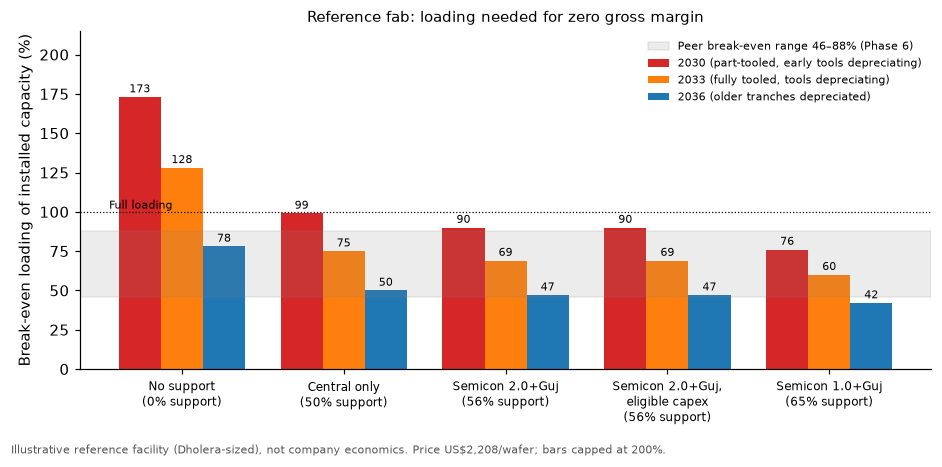

In [9]:
fig, ax = plt.subplots(figsize=(8.6, 4.2))
xs = np.arange(len(fab_be)); wdt = 0.26
for k, (col, lab, colr) in enumerate([('GM_breakeven_loading_2030_%', '2030 (part-tooled, early tools depreciating)', '#d62728'),
                                     ('GM_breakeven_loading_2033_%', '2033 (fully tooled, tools depreciating)', '#ff7f0e'),
                                     ('GM_breakeven_loading_2036_%', '2036 (older tranches depreciated)', '#1f77b4')]):
    vals = fab_be[col].clip(upper=200)
    ax.bar(xs + (k - 1) * wdt, vals, wdt, color=colr, label=lab)
    for x_, v_ in zip(xs + (k - 1) * wdt, fab_be[col]):
        ax.text(x_, min(v_, 200) + 3, f'{v_:.0f}', ha='center', fontsize=7)
ax.axhspan(46, 88, color='grey', alpha=0.15, label='Peer break-even range 46–88% (Phase 6)')
ax.axhline(100, color='black', lw=0.8, ls=':'); ax.text(-0.45, 102, 'Full loading', fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels([f"{c}\n({s}% support)" for c, s in zip(['No support', 'Central only', 'Semicon 2.0+Guj', 'Semicon 2.0+Guj,\neligible capex', 'Semicon 1.0+Guj'], fab_be['support_%'])], fontsize=8)
ax.set_ylabel('Break-even loading of installed capacity (%)'); ax.set_ylim(0, 215)
ax.set_title('Reference fab: loading needed for zero gross margin', fontsize=10)
ax.legend(fontsize=7, frameon=False, loc='upper right')
fig.text(0.01, 0.005, 'Illustrative reference facility (Dholera-sized), not company economics. Price US$2,208/wafer; bars capped at 200%.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart_fab_breakeven.png', dpi=200); plt.show()

**Reading this:**
- **Without support:** the reference fab cannot reach zero gross margin while its tools are being depreciated. It needs about 128% loading in 2033, which is impossible, because five-year tool depreciation on a ~US$9.6 billion project is larger than the margin the wafers earn. Only after the early tools are fully depreciated (2036) does break-even fall to about 78%, the level of PSMC or Hua Hong.
- **With ~65% support (Semicon 1.0 + Gujarat):** the 2033 break-even falls to about 60%, inside the peer range and a little below the peer median (66%). By 2036 it is about 42%, like the old, depreciated fabs (UMC/VIS ~46%).
- **Semicon 2.0's maximum (56%):** about 69% in 2033, still workable. Central support alone (50%): about 75%.

This puts numbers on Phase 6's claim that the subsidy pulls break-even down. It moves the 2033 break-even from impossible to about where a normal mature foundry sits.

The **cash** break-even is much lower. Once loaded, the fab covers its cash costs well before it covers depreciation. So the risk in the early years is accounting losses and slow payback, not running out of cash on operations.

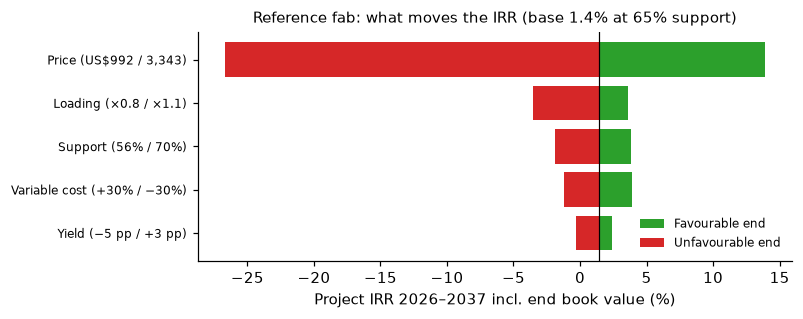

,input,low_case_irr_%,high_case_irr_%,swing
2,Yield (−5 pp / +3 pp),-0.3,2.4,2.7
3,Variable cost (+30% / −30%),-1.2,3.9,5.1
4,Support (56% / 70%),-1.9,3.8,5.7
0,Loading (×0.8 / ×1.1),-3.5,3.6,7.1
1,"Price (US$992 / 3,343)",-26.7,13.9,40.6


In [10]:
irr_base = fab(0.65)[1]
tests = [('Loading (×0.8 / ×1.1)', dict(load_mult=0.8), dict(load_mult=1.1)),
         ('Price (US$992 / 3,343)', dict(price=P_MIN), dict(price=P_MAX)),
         ('Yield (−5 pp / +3 pp)', dict(yield_add=-0.05), dict(yield_add=0.03)),
         ('Variable cost (+30% / −30%)', dict(var_mult=1.3), dict(var_mult=0.7)),
         ('Support (56% / 70%)', None, None)]
tor_f = []
for lab, lo_kw, hi_kw in tests:
    if lo_kw is None:
        lo, hi = fab(0.56)[1], fab(0.70)[1]
    else:
        lo, hi = fab(0.65, **lo_kw)[1], fab(0.65, **hi_kw)[1]
    tor_f.append({'input': lab, 'low_case_irr_%': round(100 * lo, 1), 'high_case_irr_%': round(100 * hi, 1)})
tor_f = pd.DataFrame(tor_f); tor_f['swing'] = (tor_f['high_case_irr_%'] - tor_f['low_case_irr_%']).abs(); tor_f = tor_f.sort_values('swing')
b0 = 100 * irr_base
fig, ax = plt.subplots(figsize=(7.4, 3.0)); yy = np.arange(len(tor_f))
ax.barh(yy, tor_f['high_case_irr_%'] - b0, left=b0, color='#2ca02c', label='Favourable end')
ax.barh(yy, tor_f['low_case_irr_%'] - b0, left=b0, color='#d62728', label='Unfavourable end')
ax.axvline(b0, color='black', lw=0.8); ax.set_yticks(yy); ax.set_yticklabels(tor_f['input'], fontsize=8)
ax.set_xlabel('Project IRR 2026–2037 incl. end book value (%)'); ax.set_title(f'Reference fab: what moves the IRR (base {b0:.1f}% at 65% support)', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('../charts/chart_fab_tornado.png', dpi=200); plt.show()
tor_f

In [11]:
sens = []
for eq in [0.50, 0.575, 0.65]:
    for tl in [5, 6]:
        df, r_, pb, tv = fab(0.65, equip=eq, building=min(0.30, 1 - eq - 0.05), tool_life=tl)
        sens.append({'equipment_share_%': round(100 * eq, 1), 'building_share_%': round(100 * min(0.30, 1 - eq - 0.05)), 'tool_life_yrs': tl,
                     'GM_breakeven_2033_%': round(breakeven_loading(df, 2033)[0]), 'gross_margin_2033_%': round(100 * df[df.year == 2033]['gross_profit_usd_m'].iloc[0] / df[df.year == 2033]['revenue_usd_m'].iloc[0]),
                     'project_irr_%': round(100 * r_, 1)})
sens = pd.DataFrame(sens)
print('Capex split and tool life sensitivity (65% support). When equipment rises above 65%, building is capped so that other stays >= 5%.')
sens

Capex split and tool life sensitivity (65% support). When equipment rises above 65%, building is capped so that other stays >= 5%.


,equipment_share_%,building_share_%,tool_life_yrs,GM_breakeven_2033_%,gross_margin_2033_%,project_irr_%
0,50.0,30,5,60,23,1.4
1,50.0,30,6,57,25,1.7
2,57.5,30,5,64,18,1.5
3,57.5,30,6,62,21,1.8
4,65.0,30,5,69,14,1.6
5,65.0,30,6,66,17,2.0


**Reading this:**
- **IRR drivers:** price and loading dominate the fab's IRR, just as they did in the Phase 6 output simulation. The support rate between 56% and 70% matters less than either.
- **Capex split:** a higher equipment share raises 2033 depreciation and the break-even loading. A six-year tool life lowers both. The conclusion (support brings break-even into the peer range) holds across the 50–65% equipment range.
- **IRR level:** even with ~65% support, the 2026–37 IRR is only about 1% and there is no payback by 2037, because the fab is fully tooled only in 2033. Over a 20-year operating life (with sustaining capex at 10% of revenue) the IRR with 65% support is in the table above. Without support it stays negative on both views. The fab is a long-payback, strategic asset. A private investor without support would not build it on these numbers, which is why the countries in Phase 4 that are adding fabs all subsidise them.

## Part 4 – Correlated Monte Carlo (Sanand and Dholera)

In Phases 5 and 6 every input was drawn independently, so a low loading often got paired with an average price, and the extremes cancelled out. In a real chip cycle, loading and price move together.

Method (a "Gaussian copula", explainable in three steps):
1. Draw two normal numbers with correlation ρ: `z2 = ρ·z1 + √(1−ρ²)·e`.
2. Turn each into a uniform number between 0 and 1 with the normal CDF, Φ(z).
3. Feed those uniforms into the same triangular distributions as before (inverse triangular CDF).

I run ρ = 0 (independent), ρ = 0.7 (stated, strong but not perfect) and ρ = 1 (fully correlated, as in Phase 5). The same seed is used throughout.

In [12]:
Phi = np.vectorize(lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2))))
def tri_inv(u, a, c, b):
    f = (c - a) / (b - a)
    return np.where(u < f, a + np.sqrt(u * (b - a) * (c - a)), b - np.sqrt((1 - u) * (b - a) * (b - c)))
def corr_uniforms(rho, n, rng):
    z1 = rng.standard_normal(n); e = rng.standard_normal(n)
    z2 = rho * z1 + math.sqrt(max(1 - rho ** 2, 0)) * e
    return Phi(z1), Phi(z2)

N = 10_000
si = pd.read_csv('../data/sanand_inputs.csv').set_index('input')
tr = lambda k, u: tri_inv(u, *si.loc[k, ['low', 'mode', 'high']].astype(float))
CAP_S = float(si.loc['capacity_units', 'mode'])
def vpu(d, s, pd_, pn, ps): return d * pd_ + (1 - d - s) * pn + s * ps

rows = []
for rho in [0.0, 0.7, 1.0]:
    rng = np.random.default_rng(42)
    u_util, u_price = corr_uniforms(rho, N, rng)
    other = rng.random((3, N))                          # mix shares drawn independently
    # one price driver moves all three memory prices together (they share one cycle)
    val = tr('utilisation_2030', u_util) * CAP_S * vpu(tr('dram_share_units', other[0]), tr('ssd_share_units', other[1]),
          tr('dram_value_per_chip_usd', u_price), tr('nand_value_per_package_usd', u_price), tr('ssd_value_per_unit_usd', u_price)) / 1000
    rows.append({'model': 'Sanand 2030 throughput value (US$B)', 'rho': rho, **dict(zip(['P10', 'P50', 'P90'], np.percentile(val, [10, 50, 90]).round(2)))})

di = pd.read_csv('../data/dholera_inputs.csv')
peers = pd.read_csv('../data/foundry_peers.csv')
ship12 = np.where(peers['shipment_unit'].str.startswith('8-inch', na=False), peers['shipments_k'] / 2.25, peers['shipments_k'])
rpw = (peers['revenue_usd_m'] * 1e6 / (ship12 * 1e3)).dropna()
PR = [rpw.min(), rpw.median(), rpw.max()]
util_peer = peers.dropna(subset=['utilisation_pct', 'gross_margin_pct'])['utilisation_pct']
def drow(name, year):
    r = di[(di['input'] == name) & (di['year'].astype(str) == str(year))].iloc[0]
    sub = {'peer_min': util_peer.min() / 100, 'peer_median': util_peer.median() / 100}
    return [float(sub.get(x, x)) for x in (r['low'], r['mode'], r['high'])]
for y in [2030, 2032]:
    for rho in [0.0, 0.7, 1.0]:
        rng = np.random.default_rng(42)
        u_util, u_price = corr_uniforms(rho, N, rng)
        u_yield = rng.random(N)
        val = 600000 * tri_inv(u_util, *drow('utilisation', y)) * tri_inv(u_yield, *drow('yield', y)) * tri_inv(u_price, *PR) / 1e6
        rows.append({'model': f'Dholera {y} illustrative value (US$M)', 'rho': rho, **dict(zip(['P10', 'P50', 'P90'], np.percentile(val, [10, 50, 90]).round(0)))})
corr = pd.DataFrame(rows)
corr['P90/P10'] = (corr['P90'] / corr['P10']).round(2)
corr

,model,rho,P10,P50,P90,P90/P10
0,Sanand 2030 throughput value (US$B),0.0,3.36,5.17,7.71,2.29
1,Sanand 2030 throughput value (US$B),0.7,2.91,5.23,8.71,2.99
2,Sanand 2030 throughput value (US$B),1.0,2.72,5.18,9.06,3.33
3,Dholera 2030 illustrative value (US$M),0.0,187.00,319.00,507.00,2.71
4,Dholera 2030 illustrative value (US$M),0.7,156.00,324.00,580.00,3.72
5,Dholera 2030 illustrative value (US$M),1.0,143.00,324.00,611.00,4.27
6,Dholera 2032 illustrative value (US$M),0.0,542.00,813.00,1135.00,2.09
7,Dholera 2032 illustrative value (US$M),0.7,477.00,824.00,1252.00,2.62
8,Dholera 2032 illustrative value (US$M),1.0,444.00,828.00,1296.00,2.92


**Reading this (two lines):**
- When utilisation and price move together, bad years are bad on both counts and good years good on both. So P10 falls, P90 rises, and the band widens, while P50 barely moves.
- The hand-built conservative and optimistic scenarios in Phases 5 and 6 sit close to the ρ = 1 band. The ρ = 0.7 case is the one I would quote as "realistic uncertainty".

*Note:* the ρ = 0 Sanand row differs slightly from Phase 5's 3.61 / 5.23 / 7.28, because here the three memory prices share one driver (one memory cycle), while in Phase 5 they were drawn separately.

## Part 5 – India 2030: how much of the market is local?

Market (Phase 2): US$80 / 96 / 119 billion.

Local supply from all approved units (corrected), on three measures:
- **(a) Value made or packaged in India:**
  - Micron = throughput value (Phase 5);
  - Dholera = illustrative wafer value (Phase 6, P10/P50/P90);
  - merchant OSATs = packaging revenue (corrected ratio 0.625 × capex, at 40/60/80% of ramp). For OSATs this is only the packaging fee, not the full chip value, so (a) is a lower bound.
- **(b) Value supplied to Indian buyers:** (a) × domestic share. Micron 10/20/30% (Phase 5); Dholera and merchant OSATs 20/30/40% (assumption: Qualcomm, Nexperia and Renesas serve both Indian and global customers).
- **(c) Value added in India:**
  - Micron: 12% back-end share × 45% local (Phase 5).
  - Merchant OSAT: 45% of revenue (1 − 55% imported materials, Amkor).
  - Dholera: 60% of revenue (assumption: revenue minus ~26% materials, from UMC's variable cost share, and ~15% licence fees and imported services).

In [13]:
tk = pd.read_csv('../data/tracker_corrected.csv')
osat_rows = tk[~tk['company'].str.contains('Micron|Dholera|Crystal Matrix') & (tk['unit_type'] != 'Silicon fab')]
OSAT_CAPEX = osat_rows['investment_rs_cr'].sum()
print('Merchant OSAT/ATMP units counted:', ', '.join(osat_rows['company'].str.split(' ').str[0]), f'| capex Rs{OSAT_CAPEX:,.0f} Cr')
osat_full = OSAT_CAPEX * 1e7 / FX * RATIO / 1e9           # US$B at full ramp
mkt = {'Conservative': 80, 'Base': 96, 'Optimistic': 119}
micron = {'Conservative': 1.93, 'Base': 4.65, 'Optimistic': 9.54}           # Phase 5 hand-built
dhol = {'Conservative': 0.19, 'Base': 0.32, 'Optimistic': 0.50}             # Phase 6 MC P10/P50/P90 2030
ramp = {'Conservative': 0.40, 'Base': 0.60, 'Optimistic': 0.80}
dom_m = {'Conservative': 0.10, 'Base': 0.20, 'Optimistic': 0.30}
dom_o = {'Conservative': 0.20, 'Base': 0.30, 'Optimistic': 0.40}
out = []
for sc in mkt:
    o = osat_full * ramp[sc]
    a = micron[sc] + dhol[sc] + o
    b = micron[sc] * dom_m[sc] + (dhol[sc] + o) * dom_o[sc]
    c = micron[sc] * 0.12 * 0.45 + o * 0.45 + dhol[sc] * 0.60
    out.append({'scenario': sc, 'market_usd_b': mkt[sc], 'micron_usd_b': micron[sc], 'dholera_usd_b': dhol[sc], 'merchant_osat_usd_b': round(o, 2),
                'a_made_or_packaged_usd_b': round(a, 2), 'a_%': round(100 * a / mkt[sc], 1),
                'b_supplied_to_india_usd_b': round(b, 2), 'b_%': round(100 * b / mkt[sc], 1),
                'c_value_added_usd_b': round(c, 2), 'c_%': round(100 * c / mkt[sc], 1)})
india = pd.DataFrame(out)
print(f'Merchant OSAT full-ramp revenue: US${osat_full:.2f}B')
india

Merchant OSAT/ATMP units counted: Tata, CG, Kaynes, India, SiCSem, 3D, Continental, ASIP, Suchi | capex Rs47,183 Cr
Merchant OSAT full-ramp revenue: US$3.10B


,scenario,market_usd_b,micron_usd_b,dholera_usd_b,merchant_osat_usd_b,a_made_or_packaged_usd_b,a_%,b_supplied_to_india_usd_b,b_%,c_value_added_usd_b,c_%
0,Conservative,80,1.93,0.19,1.24,3.36,4.2,0.48,0.6,0.78,1.0
1,Base,96,4.65,0.32,1.86,6.83,7.1,1.58,1.7,1.28,1.3
2,Optimistic,119,9.54,0.50,2.48,12.52,10.5,4.06,3.4,1.93,1.6


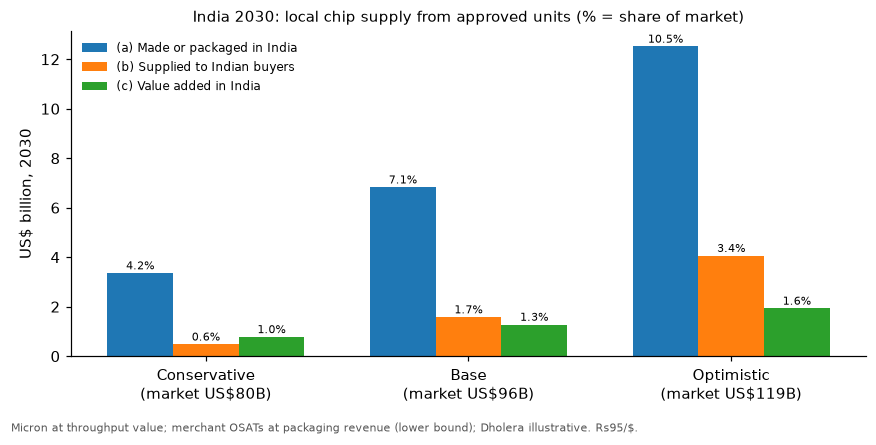

In [14]:
fig, ax = plt.subplots(figsize=(8.0, 4.0))
xs = np.arange(3); wdt = 0.25
for k, (col, pc, lab, colr) in enumerate([('a_made_or_packaged_usd_b', 'a_%', '(a) Made or packaged in India', '#1f77b4'),
                                          ('b_supplied_to_india_usd_b', 'b_%', '(b) Supplied to Indian buyers', '#ff7f0e'),
                                          ('c_value_added_usd_b', 'c_%', '(c) Value added in India', '#2ca02c')]):
    ax.bar(xs + (k - 1) * wdt, india[col], wdt, color=colr, label=lab)
    for x_, v_, p_ in zip(xs + (k - 1) * wdt, india[col], india[pc]):
        ax.text(x_, v_ + 0.15, f'{p_:.1f}%', ha='center', fontsize=7)
ax.set_xticks(xs); ax.set_xticklabels([f"{s}\n(market US${m}B)" for s, m in zip(india['scenario'], india['market_usd_b'])])
ax.set_ylabel('US$ billion, 2030'); ax.set_title('India 2030: local chip supply from approved units (% = share of market)', fontsize=10)
ax.legend(fontsize=8, frameon=False, loc='upper left')
fig.text(0.01, 0.005, 'Micron at throughput value; merchant OSATs at packaging revenue (lower bound); Dholera illustrative. Rs95/$.', fontsize=7, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig('../charts/chart_india_2030_local_supply.png', dpi=200); plt.show()

**Reading this:** in the base case:
- about 7% of India's 2030 chip market is made or packaged in India, two-thirds of it Micron's throughput;
- under 2% is supplied to Indian buyers;
- about 1.3% is value added in India.

Even the optimistic case keeps value added under 2%. This is the clearest single answer to criterion A (domestic manufacturing contribution). India will package a visible share of chips by 2030, but it will still import almost all of the value.

In [15]:
osat_cases.to_csv('../data/osat_reference_cases.csv', index=False)
tor_o.to_csv('../data/osat_tornado.csv', index=False)
base_df.round(1).to_csv('../data/fab_reference_base_65pct.csv', index=False)
fab_be.to_csv('../data/fab_reference_cases.csv', index=False)
tor_f.to_csv('../data/fab_tornado.csv', index=False)
sens.to_csv('../data/fab_capex_split_sensitivity.csv', index=False)
corr.to_csv('../data/montecarlo_correlated.csv', index=False)
india.to_csv('../data/india_2030_local_supply.csv', index=False)
print('Saved 8 output CSVs.')

Saved 8 output CSVs.


**Limitations**
- **Reference facilities:** these are built from peer cost structures (Amkor, UMC) and disclosed project sizes. They are not Tata, CG or Micron accounts.
- **What is left out:** taxes, working capital, financing, ramp-up losses beyond the cost template, and OSAT replacement capex. The OSAT IRR is overstated by excluding replacement capex in years 8–10. The fab IRR depends on the terminal book value.
- **Power:** JETRO's Ahmedabad power rate is the energy charge only, so India's power advantage is overstated.
- **Labour comparison:** Korea and Japan are missing from the survey, so India's labour advantage versus Amkor's full footprint is understated. The two effects are small next to the subsidy.
- **Fab costs:** the fab's fixed cash cost scales with installed tools. Real start-up overheads (staff hired before tools, utilities for the whole site) would raise 2028–30 costs.
- **Part 5:** the domestic shares and Dholera's 60% value-added share are assumptions.